In [1]:
import gc
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm


# Locate repository root by walking upward until datasets/ exists.
PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "datasets").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError(
            "Could not locate repository root containing datasets/"
        )

    PROJECT_ROOT = PROJECT_ROOT.parent


RQ1_DIR = (
    PROJECT_ROOT
    / "notebooks"
    / "evaluation-RQ1"
)


for path in [PROJECT_ROOT, RQ1_DIR]:
    path_str = str(path)

    if path_str not in sys.path:
        sys.path.insert(0, path_str)


TESTSET_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "dbpedia_testset_RQ1.json"
)

RESULTS_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "result_sets_dbpedia.json"
)

SPARQLCE_CKPT = (
    PROJECT_ROOT
    / "sparqlce"
    / "models"
    / "final_model_mrr_0.4487.pt"
)

OUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "threshold_sensitivity"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


TAUS = [0.6, 0.7, 0.8, 0.9]

TOPK = 10

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# Keep this list identical to the baselines used
# in the paper's RQ1 evaluation.
#
# Add/remove entries here if the original RQ1
# notebooks use a different set.
BASELINES = [
    {
        "name": "E5-base-v2",
        "model_id": "intfloat/e5-base-v2",
        "prefix": "query: ",
        "batch_size": 32,
    },
    {
        "name": "Qwen3-Embedding",
        "model_id": "Qwen/Qwen3-Embedding-0.6B",
        "prefix": "",
        "batch_size": 8,
    },
]


print(f"project root: {PROJECT_ROOT}")
print(f"device: {DEVICE}")
print(f"output dir: {OUT_DIR}")


for required_path in [
    TESTSET_PATH,
    RESULTS_PATH,
    SPARQLCE_CKPT,
]:
    status = (
        "OK"
        if required_path.exists()
        else "MISSING"
    )

    print(f"{required_path}: {status}")


if not TESTSET_PATH.exists():
    raise FileNotFoundError(TESTSET_PATH)


if not RESULTS_PATH.exists():
    raise FileNotFoundError(RESULTS_PATH)


if not SPARQLCE_CKPT.exists():
    raise FileNotFoundError(
        f"SparqlCE checkpoint not found: "
        f"{SPARQLCE_CKPT}"
    )

project root: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings
device: cuda
output dir: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/threshold_sensitivity
/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/datasets/dbpedia_testset_RQ1.json: OK
/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/datasets/result_sets_dbpedia.json: OK
/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/sparqlce/models/final_model_mrr_0.4487.pt: OK


/upb/users/g/ganeshk/profiles/unix/cs/.conda/envs/sparql/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def canonicalize_row(row) -> str:
    """
    Convert a JSON result row into a stable,
    hashable representation.

    Works whether rows are strings, lists,
    dictionaries, or scalar JSON values.
    """
    return json.dumps(
        row,
        sort_keys=True,
        ensure_ascii=False,
        separators=(",", ":"),
    )


with open(
    RESULTS_PATH,
    encoding="utf-8",
) as f:
    raw_result_sets = json.load(f)


result_sets = {
    q: frozenset(
        canonicalize_row(row)
        for row in rows
    )
    for q, rows in raw_result_sets.items()
    if rows
}


# Fallback lookup for harmless leading/trailing
# whitespace differences in query strings.
_result_sets_stripped = {}

_strip_collisions = set()


for q, rs in result_sets.items():
    key = q.strip()

    if (
        key in _result_sets_stripped
        and _result_sets_stripped[key] != rs
    ):
        _strip_collisions.add(key)

    else:
        _result_sets_stripped[key] = rs


# Do not use ambiguous stripped keys.
for key in _strip_collisions:
    _result_sets_stripped.pop(
        key,
        None,
    )


def get_result_set(query):
    """
    Return the cached non-empty result set
    for a query, or None.
    """
    rs = result_sets.get(query)

    if rs is not None:
        return rs


    if isinstance(query, str):
        return _result_sets_stripped.get(
            query.strip()
        )


    return None


def jaccard(
    a: frozenset,
    b: frozenset,
) -> float:
    """
    Jaccard overlap without materializing
    the union set.
    """
    intersection_size = len(a & b)

    union_size = (
        len(a)
        + len(b)
        - intersection_size
    )

    return (
        intersection_size / union_size
        if union_size
        else 0.0
    )


print(
    "queries with non-empty result sets: "
    f"{len(result_sets):,}"
)

print(
    "stripped-key collisions ignored: "
    f"{len(_strip_collisions):,}"
)

queries with non-empty result sets: 1,677
stripped-key collisions ignored: 0


In [7]:
queries = list(result_sets)

sets = [
    result_sets[q]
    for q in queries
]


n_pairs = (
    len(sets)
    * (len(sets) - 1)
    // 2
)


pair_j = np.empty(
    n_pairs,
    dtype=np.float32,
)


k = 0


for i in tqdm(
    range(len(sets) - 1),
    desc="pairwise Jaccard",
):
    Ri = sets[i]


    for j in range(
        i + 1,
        len(sets),
    ):
        pair_j[k] = jaccard(
            Ri,
            sets[j],
        )

        k += 1


assert k == n_pairs


grey = float(
    np.mean(
        (pair_j >= 0.2)
        & (pair_j <= 0.8)
    )
)

lo = float(
    np.mean(
        pair_j < 0.2
    )
)

hi = float(
    np.mean(
        pair_j > 0.8
    )
)


print(
    f"pairs: {len(pair_j):,}"
)

print(
    f"Jaccard < 0.2 : "
    f"{lo:.2%}   "
    f"(negative region)"
)

print(
    f"0.2–0.8 grey  : "
    f"{grey:.2%}   "
    f"<-- paper number"
)

print(
    f"Jaccard > 0.8 : "
    f"{hi:.2%}   "
    f"(positive region)"
)


np.save(
    OUT_DIR
    / "pairwise_jaccard_dbpedia.npy",
    pair_j,
)


# --------------------------------------------------
# Nearby-cut counts
# --------------------------------------------------
#
# These directly show how much the selected
# positive/negative populations move when nearby
# cutoffs are used.

threshold_rows = []


for threshold in [
    0.7,
    0.8,
    0.9,
]:
    count = int(
        np.sum(
            pair_j > threshold
        )
    )

    threshold_rows.append(
        {
            "side": "positive",
            "rule": (
                f"J > {threshold:.1f}"
            ),
            "threshold": threshold,
            "count": count,
            "fraction_of_all_pairs": (
                count / len(pair_j)
            ),
        }
    )


for threshold in [
    0.1,
    0.2,
    0.3,
]:
    count = int(
        np.sum(
            pair_j < threshold
        )
    )

    threshold_rows.append(
        {
            "side": "negative",
            "rule": (
                f"J < {threshold:.1f}"
            ),
            "threshold": threshold,
            "count": count,
            "fraction_of_all_pairs": (
                count / len(pair_j)
            ),
        }
    )


threshold_counts = pd.DataFrame(
    threshold_rows
)


display(
    threshold_counts
)


threshold_counts.to_csv(
    OUT_DIR
    / "jaccard_nearby_threshold_counts_dbpedia.csv",
    index=False,
)


summary_a = {
    "n_queries_nonempty": (
        len(result_sets)
    ),
    "n_pairs": (
        len(pair_j)
    ),
    "fraction_j_lt_0_2": lo,
    "fraction_grey_0_2_to_0_8_inclusive": (
        grey
    ),
    "fraction_j_gt_0_8": hi,
}


with open(
    OUT_DIR
    / "jaccard_distribution_summary_dbpedia.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        summary_a,
        f,
        indent=2,
    )


print(
    "saved Experiment A numeric outputs"
)

pairwise Jaccard: 100%|██████████| 1676/1676 [00:00<00:00, 2936.23it/s]

pairs: 1,405,326
Jaccard < 0.2 : 96.58%   (negative region)
0.2–0.8 grey  : 2.61%   <-- paper number
Jaccard > 0.8 : 0.81%   (positive region)


,side,rule,threshold,count,fraction_of_all_pairs
0,positive,J > 0.7,0.7,15187,0.010807
1,positive,J > 0.8,0.8,11360,0.008084
2,positive,J > 0.9,0.9,8062,0.005737
3,negative,J < 0.1,0.1,1352412,0.962348
4,negative,J < 0.2,0.2,1357324,0.965843
5,negative,J < 0.3,0.3,1365578,0.971716


saved Experiment A numeric outputs


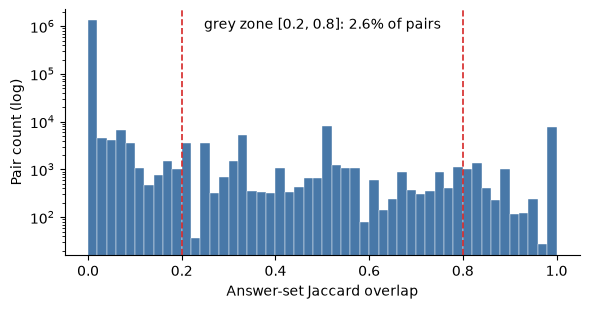

saved: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/threshold_sensitivity/jaccard_histogram_dbpedia.pdf


In [8]:
fig, ax = plt.subplots(
    figsize=(6, 3.2)
)


ax.hist(
    pair_j,
    bins=50,
    color="#4878a8",
    edgecolor="white",
    linewidth=0.3,
)


ax.set_yscale(
    "log"
)


for x in [
    0.2,
    0.8,
]:
    ax.axvline(
        x,
        color="#d62728",
        linestyle="--",
        linewidth=1.2,
    )


ax.text(
    0.5,
    0.92,
    (
        f"grey zone [0.2, 0.8]: "
        f"{grey:.1%} of pairs"
    ),
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
)


ax.set_xlabel(
    "Answer-set Jaccard overlap"
)

ax.set_ylabel(
    "Pair count (log)"
)


ax.spines[
    ["top", "right"]
].set_visible(
    False
)


fig.tight_layout()


histogram_path = (
    OUT_DIR
    / "jaccard_histogram_dbpedia.pdf"
)


fig.savefig(
    histogram_path,
    dpi=300,
    bbox_inches="tight",
)


plt.show()

plt.close(fig)


print(
    f"saved: {histogram_path}"
)

In [9]:
from evaluate_rq1 import (
    load_triplets,
    build_global_corpus,
    build_eval_items,
)


test_data = load_triplets(
    str(TESTSET_PATH)
)


global_corpus, seen_q = (
    build_global_corpus(
        test_data
    )
)


raw_eval_items = build_eval_items(
    test_data,
    global_corpus,
    seen_q,
)


# --------------------------------------------------
# Preserve original per-anchor candidate pools.
# --------------------------------------------------
#
# We only:
#
# 1. drop anchors without oracle result sets,
# 2. remove exact self matches,
# 3. deduplicate candidates while preserving order.
#
# Candidates without oracle result sets remain
# in the ranking pool.

eval_records = []


for item in raw_eval_items:
    anchor, pool, original_positives = (
        item[:3]
    )


    if get_result_set(anchor) is None:
        continue


    pool_dedup = []

    seen_candidates = set()


    for candidate in pool:

        if candidate == anchor:
            continue


        if candidate in seen_candidates:
            continue


        seen_candidates.add(
            candidate
        )

        pool_dedup.append(
            candidate
        )


    if not pool_dedup:
        continue


    eval_records.append(
        {
            "anchor": anchor,
            "pool": pool_dedup,
            "original_positives": (
                original_positives
            ),
        }
    )


anchors = [
    record["anchor"]
    for record in eval_records
]


# Union of all candidates while preserving
# first-seen order.
candidate_corpus = list(
    dict.fromkeys(
        candidate

        for record in eval_records

        for candidate in record["pool"]
    )
)


candidate_index = {
    candidate: idx

    for idx, candidate
    in enumerate(candidate_corpus)
}


pool_indices = [
    np.asarray(
        [
            candidate_index[c]
            for c in record["pool"]
        ],
        dtype=np.int32,
    )

    for record in eval_records
]


n_pool_candidates = sum(
    len(record["pool"])
    for record in eval_records
)


n_pool_candidates_with_oracle = sum(
    get_result_set(candidate) is not None

    for record in eval_records

    for candidate in record["pool"]
)


print(
    f"raw eval items: "
    f"{len(raw_eval_items):,}"
)

print(
    "usable anchors with oracle results: "
    f"{len(eval_records):,}"
)

print(
    f"unique candidate corpus: "
    f"{len(candidate_corpus):,}"
)

print(
    "total anchor-pool candidate entries: "
    f"{n_pool_candidates:,}"
)

print(
    "pool candidate entries with oracle results: "
    f"{n_pool_candidates_with_oracle:,} / "
    f"{n_pool_candidates:,} "
    f"("
    f"{n_pool_candidates_with_oracle / n_pool_candidates:.2%}"
    f")"
)

raw eval items: 337
usable anchors with oracle results: 337
unique candidate corpus: 1,677
total anchor-pool candidate entries: 564,812
pool candidate entries with oracle results: 564,812 / 564,812 (100.00%)


In [10]:
# J_pool[i][p] corresponds to:
#
#   eval_records[i]["pool"][p]
#
# NaN means the candidate has no cached
# oracle result set.

J_pool = []


for record in tqdm(
    eval_records,
    desc="pool relevance Jaccard",
):
    Ra = get_result_set(
        record["anchor"]
    )


    values = np.full(
        len(record["pool"]),
        np.nan,
        dtype=np.float32,
    )


    for p, candidate in enumerate(
        record["pool"]
    ):
        Rc = get_result_set(
            candidate
        )


        if Rc is not None:
            values[p] = jaccard(
                Ra,
                Rc,
            )


    J_pool.append(
        values
    )


# --------------------------------------------------
# Coverage diagnostic
# --------------------------------------------------
#
# How many anchors have at least one relevant
# candidate at each tau?

coverage_rows = []


for tau in TAUS:

    n_with_relevant = sum(
        bool(
            np.any(
                np.isfinite(values)
                & (values >= tau)
            )
        )

        for values in J_pool
    )


    coverage_rows.append(
        {
            "tau": tau,
            "anchors_total": (
                len(eval_records)
            ),
            "anchors_with_at_least_one_relevant_candidate": (
                n_with_relevant
            ),
            "coverage": (
                n_with_relevant
                / len(eval_records)
            ),
        }
    )


coverage = pd.DataFrame(
    coverage_rows
)


display(
    coverage
)


coverage.to_csv(
    OUT_DIR
    / "tau_anchor_coverage_dbpedia.csv",
    index=False,
)


# --------------------------------------------------
# Fixed evaluation population
# --------------------------------------------------
#
# Use the same anchors for every tau.
#
# We retain anchors that have at least one relevant
# candidate at the strictest threshold, max(TAUS).
#
# Therefore every retained anchor has at least one
# relevant candidate at all lower thresholds too.

max_tau = max(
    TAUS
)


fixed_eval_indices = np.asarray(
    [
        i

        for i, values
        in enumerate(J_pool)

        if np.any(
            np.isfinite(values)
            & (values >= max_tau)
        )
    ],
    dtype=np.int32,
)


if len(fixed_eval_indices) == 0:
    raise RuntimeError(
        f"No anchors have a relevant candidate "
        f"at tau={max_tau}. "
        f"Inspect "
        f"tau_anchor_coverage_dbpedia.csv."
    )


print(
    "fixed evaluation population: "
    f"{len(fixed_eval_indices):,} anchors "
    f"(eligible at tau={max_tau})"
)

pool relevance Jaccard: 100%|██████████| 337/337 [00:00<00:00, 1059.90it/s]


,tau,anchors_total,anchors_with_at_least_one_relevant_candidate,coverage
0,0.6,337,313,0.928783
1,0.7,337,312,0.925816
2,0.8,337,310,0.919881
3,0.9,337,301,0.893175


fixed evaluation population: 301 anchors (eligible at tau=0.9)


In [11]:
from sentence_transformers import (
    SentenceTransformer
)

from sparqlce.embedder import (
    SPARQLEmbedder
)


def as_numpy_2d(x):
    """
    Convert model output to a 2D
    float32 NumPy array.
    """

    if torch.is_tensor(x):
        x = (
            x.detach()
            .cpu()
            .numpy()
        )


    x = np.asarray(
        x,
        dtype=np.float32,
    )


    if x.ndim == 1:
        x = x[None, :]


    if x.ndim != 2:
        raise ValueError(
            f"expected 2D embeddings, "
            f"got shape {x.shape}"
        )


    return x


def l2_normalize(x):
    x = np.asarray(
        x,
        dtype=np.float32,
    )


    norms = np.linalg.norm(
        x,
        axis=1,
        keepdims=True,
    )


    norms = np.clip(
        norms,
        1e-12,
        None,
    )


    return x / norms


def embed_sparqlce(
    model,
    texts,
    batch_size=32,
):
    batches = []


    for start in tqdm(
        range(
            0,
            len(texts),
            batch_size,
        ),
        desc="SparqlCE embedding",
        leave=False,
    ):
        batch_texts = texts[
            start : start + batch_size
        ]


        batch_embeddings = model.encode(
            batch_texts
        )


        batches.append(
            as_numpy_2d(
                batch_embeddings
            )
        )


    return l2_normalize(
        np.vstack(batches)
    )


model_sims = {}


# ==================================================
# SparqlCE
# ==================================================

print("\nLoading SparqlCE...")


sparqlce = SPARQLEmbedder(
    str(SPARQLCE_CKPT)
)


print("Embedding anchors with SparqlCE...")


A = embed_sparqlce(
    sparqlce,
    anchors,
    batch_size=32,
)


print("Embedding candidate corpus with SparqlCE...")


C = embed_sparqlce(
    sparqlce,
    candidate_corpus,
    batch_size=32,
)


model_sims["SparqlCE"] = (
    A @ C.T
).astype(
    np.float32,
    copy=False,
)


del sparqlce
del A
del C


gc.collect()


if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ==================================================
# Baselines
# ==================================================

for config in BASELINES:

    name = config["name"]

    model_id = config["model_id"]

    prefix = config.get(
        "prefix",
        "",
    )

    batch_size = config.get(
        "batch_size",
        32,
    )


    print(
        f"\nEmbedding with "
        f"{name} ({model_id})"
    )


    model = SentenceTransformer(
        model_id,
        device=DEVICE,
    )


    anchor_inputs = [
        prefix + q
        for q in anchors
    ]


    candidate_inputs = [
        prefix + q
        for q in candidate_corpus
    ]


    A = model.encode(
        anchor_inputs,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True,
        batch_size=batch_size,
    ).astype(
        np.float32,
        copy=False,
    )


    C = model.encode(
        candidate_inputs,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True,
        batch_size=batch_size,
    ).astype(
        np.float32,
        copy=False,
    )


    model_sims[name] = (
        A @ C.T
    ).astype(
        np.float32,
        copy=False,
    )


    del model
    del A
    del C
    del anchor_inputs
    del candidate_inputs


    gc.collect()


    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print(
    "\nsimilarity matrix shapes:"
)


for name, sims in model_sims.items():
    print(
        f"  {name}: {sims.shape}"
    )


expected_shape = (
    len(anchors),
    len(candidate_corpus),
)


for name, sims in model_sims.items():

    if sims.shape != expected_shape:
        raise RuntimeError(
            f"{name} similarity matrix "
            f"has shape {sims.shape}; "
            f"expected {expected_shape}"
        )


Loading SparqlCE...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 37025.53it/s]


Loading model from /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/sparqlce/models/final_model_mrr_0.4487.pt...
Embedding anchors with SparqlCE...


Embedding candidate corpus with SparqlCE...



Embedding with E5-base-v2 (intfloat/e5-base-v2)


Batches: 100%|██████████| 53/53 [00:02<00:00, 17.89it/s]



Embedding with Qwen3-Embedding (Qwen/Qwen3-Embedding-0.6B)


Batches: 100%|██████████| 210/210 [00:06<00:00, 32.62it/s]



similarity matrix shapes:
  SparqlCE: (337, 1677)
  E5-base-v2: (337, 1677)
  Qwen3-Embedding: (337, 1677)


In [12]:
def rank_pools_once(
    sims,
    pool_indices,
):
    """
    Return one local ranking per anchor.

    Each returned array contains local positions
    into that anchor's own candidate pool,
    sorted from highest to lowest similarity.
    """

    rankings = []


    for i, indices in enumerate(
        pool_indices
    ):
        pool_scores = sims[
            i,
            indices,
        ]


        # Stable sort makes exact ties deterministic.
        local_order = np.argsort(
            -pool_scores,
            kind="stable",
        )


        rankings.append(
            local_order
        )


    return rankings


model_rankings = {
    name: rank_pools_once(
        sims,
        pool_indices,
    )

    for name, sims
    in model_sims.items()
}


print(
    "rankings precomputed for:",
    list(model_rankings),
)

rankings precomputed for: ['SparqlCE', 'E5-base-v2', 'Qwen3-Embedding']


In [13]:
def mrr_hits_at_k_from_rankings(
    rankings,
    jaccard_by_pool,
    tau,
    k,
    eval_indices,
):
    """
    Evaluate a fixed set of anchors.

    Relevance:
        candidate is relevant iff
        answer-set Jaccard >= tau.

    The same eval_indices are used at every tau,
    so the denominator does not change.
    """

    reciprocal_ranks = []

    hits = []


    for i in eval_indices:

        relevant = (
            np.isfinite(
                jaccard_by_pool[i]
            )
            & (
                jaccard_by_pool[i]
                >= tau
            )
        )


        if not relevant.any():
            raise RuntimeError(
                f"anchor index {i} has no "
                f"relevant candidate at tau={tau}; "
                f"the fixed evaluation population "
                f"is inconsistent"
            )


        top_local_positions = (
            rankings[i][:k]
        )


        relevant_in_topk = (
            relevant[
                top_local_positions
            ]
        )


        hit_positions = np.flatnonzero(
            relevant_in_topk
        )


        if len(hit_positions):

            rank = (
                int(hit_positions[0])
                + 1
            )


            reciprocal_ranks.append(
                1.0 / rank
            )


            hits.append(
                1.0
            )


        else:

            reciprocal_ranks.append(
                0.0
            )


            hits.append(
                0.0
            )


    return (
        float(
            np.mean(
                reciprocal_ranks
            )
        ),
        float(
            np.mean(
                hits
            )
        ),
        len(
            reciprocal_ranks
        ),
    )


# ==================================================
# Run the tau sweep
# ==================================================

rows = []


for tau in TAUS:

    for model_name, rankings in (
        model_rankings.items()
    ):

        mrr, hits, n = (
            mrr_hits_at_k_from_rankings(
                rankings=rankings,
                jaccard_by_pool=J_pool,
                tau=tau,
                k=TOPK,
                eval_indices=(
                    fixed_eval_indices
                ),
            )
        )


        rows.append(
            {
                "tau": tau,
                "model": model_name,
                f"MRR@{TOPK}": mrr,
                f"Hits@{TOPK}": hits,
                "n_anchors": n,
                "population_rule": (
                    "fixed intersection: "
                    "relevant candidate exists "
                    f"at tau={max_tau}"
                ),
            }
        )


mini_long = pd.DataFrame(
    rows
)


metric_col = (
    f"MRR@{TOPK}"
)


full_mrr_pivot = (
    mini_long.pivot(
        index="tau",
        columns="model",
        values=metric_col,
    )
)


baseline_names = [
    name

    for name in model_rankings

    if name != "SparqlCE"
]


if not baseline_names:
    raise RuntimeError(
        "At least one baseline is required "
        "for the mini-table."
    )


best_baseline_mrr = (
    full_mrr_pivot[
        baseline_names
    ].max(
        axis=1
    )
)


best_baseline_name = (
    full_mrr_pivot[
        baseline_names
    ].idxmax(
        axis=1
    )
)


paper_table = pd.DataFrame(
    {
        "SparqlCE": (
            full_mrr_pivot[
                "SparqlCE"
            ]
        ),
        "best baseline": (
            best_baseline_mrr
        ),
        "best baseline model": (
            best_baseline_name
        ),
    }
)


paper_table["gap (x)"] = (
    paper_table["SparqlCE"]
    / paper_table["best baseline"]
)


paper_table["n_anchors"] = (
    len(fixed_eval_indices)
)


print(
    "\nFull MRR pivot:"
)


display(
    full_mrr_pivot.round(4)
)


print(
    "\nPaper mini-table:"
)


display(
    paper_table.round(4)
)


# ==================================================
# Save outputs
# ==================================================

mini_long.to_json(
    OUT_DIR
    / "tau_sweep_dbpedia.json",
    orient="records",
    indent=2,
)


mini_long.to_csv(
    OUT_DIR
    / "tau_sweep_dbpedia.csv",
    index=False,
)


paper_table.to_csv(
    OUT_DIR
    / "tau_sensitivity_mini_table_dbpedia.csv",
)


# ==================================================
# LaTeX rows
# ==================================================

print(
    "\nLaTeX rows:"
)


for tau, row in paper_table.iterrows():

    marker = (
        r"\;(paper)"
        if np.isclose(tau, 0.8)
        else ""
    )


    print(
        f"$\\tau={tau:.1f}${marker} & "
        f"{row['SparqlCE']:.4f} & "
        f"{row['best baseline']:.4f} & "
        f"{row['gap (x)']:.2f}"
        f"$\\times$ \\\\"
    )


Full MRR pivot:


model,E5-base-v2,Qwen3-Embedding,SparqlCE
tau,,,
0.6,0.3550,0.3830,0.6223
0.7,0.3514,0.3819,0.6151
0.8,0.3332,0.3543,0.5795
0.9,0.1806,0.2223,0.4133



Paper mini-table:


,SparqlCE,best baseline,best baseline model,gap (x),n_anchors
tau,,,,,
0.6,0.6223,0.3830,Qwen3-Embedding,1.6249,301
0.7,0.6151,0.3819,Qwen3-Embedding,1.6108,301
0.8,0.5795,0.3543,Qwen3-Embedding,1.6358,301
0.9,0.4133,0.2223,Qwen3-Embedding,1.8591,301



LaTeX rows:
$\tau=0.6$ & 0.6223 & 0.3830 & 1.62$\times$ \\
$\tau=0.7$ & 0.6151 & 0.3819 & 1.61$\times$ \\
$\tau=0.8$\;(paper) & 0.5795 & 0.3543 & 1.64$\times$ \\
$\tau=0.9$ & 0.4133 & 0.2223 & 1.86$\times$ \\


In [14]:
print(
    "Experiment A"
)

print(
    "------------"
)

print(
    "grey-zone fraction [0.2, 0.8]: "
    f"{grey:.4%}"
)

print(
    f"histogram: "
    f"{OUT_DIR / 'jaccard_histogram_dbpedia.pdf'}"
)

print(
    "nearby-threshold counts: "
    f"{OUT_DIR / 'jaccard_nearby_threshold_counts_dbpedia.csv'}"
)


print(
    "\nExperiment B"
)

print(
    "------------"
)

print(
    f"fixed evaluation anchors: "
    f"{len(fixed_eval_indices):,} "
    f"(eligible at tau={max_tau})"
)

print(
    "mini-table: "
    f"{OUT_DIR / 'tau_sensitivity_mini_table_dbpedia.csv'}"
)

print(
    "coverage table: "
    f"{OUT_DIR / 'tau_anchor_coverage_dbpedia.csv'}"
)


print(
    "\nMini-table:"
)


display(
    paper_table.round(4)
)

Experiment A
------------
grey-zone fraction [0.2, 0.8]: 2.6074%
histogram: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/threshold_sensitivity/jaccard_histogram_dbpedia.pdf
nearby-threshold counts: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/threshold_sensitivity/jaccard_nearby_threshold_counts_dbpedia.csv

Experiment B
------------
fixed evaluation anchors: 301 (eligible at tau=0.9)
mini-table: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/threshold_sensitivity/tau_sensitivity_mini_table_dbpedia.csv
coverage table: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/threshold_sensitivity/tau_anchor_coverage_dbpedia.csv

Mini-table:


,SparqlCE,best baseline,best baseline model,gap (x),n_anchors
tau,,,,,
0.6,0.6223,0.3830,Qwen3-Embedding,1.6249,301
0.7,0.6151,0.3819,Qwen3-Embedding,1.6108,301
0.8,0.5795,0.3543,Qwen3-Embedding,1.6358,301
0.9,0.4133,0.2223,Qwen3-Embedding,1.8591,301
